# 05. Modelado Avanzado y Evaluación Robusta — CRISP-DM Fases 4 y 5
**Proyecto:** Predicción del Consumo Eléctrico Mensual (ENOSA & Hidrandina)  
**Objetivo:** Desarrollar, optimizar y comparar modelos avanzados de aprendizaje automático basados en ensambles de gradiente (**LightGBM**, **XGBoost** y **CatBoost**) bajo una formulación de target residual ($\Delta \log(1+y)$), un esquema de validación temporal sin fuga de información y un estudio sistemático de granularidad arquitectónica.

### Ejes Metodológicos y de Negocio:
1. **Formulación residual logarítmica:** Predecir el cambio relativo $\Delta = \log(1 + y_{t+1}) - \log(1 + y_t)$. Si no hay señal estacional, colapsa de forma natural al benchmark de persistencia temporal ($y_{t+1} = y_t$).
2. **Validación Temporal por Bloques Calendario:** Pliegues sobre meses calendario completos (`PERIODO`), garantizando 0 solapamiento intra-mes en el cross-validation.
3. **Búsqueda Estocástica de Hiperparámetros:** `RandomizedSearchCV` sobre el conjunto `TRAIN` (hasta 2024-12).
4. **Fase de Selección del Modelo Campeón en VALIDATION:** Evaluación objetiva de los tres algoritmos en `VALIDATION` (2025-01 a 2025-03) como árbitro imparcial.
5. **Evaluación Ciega en TEST:** Reentrenamiento sobre `TRAIN + VALIDATION` y prueba final no sesgada en `TEST` (2025-04 a 2025-07).
6. **Auditoría de Ponderación:** Comparativa de Micro-Average vs. Macro-Average y error ponderado por energía física (WAPE) para descartar sesgos por desbalance.
7. **Estudio Experimental de Arquitecturas (Benchmarking de 4 Estrategias):** Evaluación sistemática para responder a la pregunta de diseño del profesor: ¿1 modelo global, modelos por distribuidora, modelos por tipo de usuario (hogares vs industrias) o matriz cruzada?
8. **Resguardo de Futuro:** Las 6,752 observaciones de `FUTURE_HOLDOUT` (2025-08 a 2026-08) se mantienen selladas.


## 1. Configuración, Carga y Feature Engineering Temporal


In [1]:
from __future__ import annotations
from pathlib import Path
import time
import json
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import lightgbm as lgb
import xgboost as xgb
import catboost as cb
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ROOT = Path.cwd().resolve()
DATASET_PATH = ROOT / 'data' / 'processed' / 'dataset_ml.parquet'
OUTPUT_DIR = ROOT / 'reports' / 'model_outputs'
MODELS_DIR = ROOT / 'models'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

data = pl.read_parquet(DATASET_PATH).to_pandas()
print(f'Dataset cargado: {data.shape[0]:,} observaciones modelables.')

# Enriquecimiento de características temporales
for df in [data]:
    df['LOG_DELTA'] = np.log1p(df['TARGET_CONSUMO_MWH']) - np.log1p(df['consumo_total_mwh'])
    df['RATIO_LAG1'] = (df['consumo_total_mwh'] + 1) / (df['lag_1'] + 1)
    df['RATIO_LAG2'] = (df['consumo_total_mwh'] + 1) / (df['lag_2'] + 1)
    df['RATIO_LAG3'] = (df['consumo_total_mwh'] + 1) / (df['lag_3'] + 1)
    df['ROLLING_MEAN_3'] = (df['consumo_total_mwh'] + df['lag_1'] + df['lag_2']) / 3.0

categorical_cols = ['DISTRIBUIDORA', 'UBIGEO', 'TARIFA']
numeric_cols = [
    'MES', 'consumo_total_mwh', 'lag_1', 'lag_2', 'lag_3',
    'RATIO_LAG1', 'RATIO_LAG2', 'RATIO_LAG3', 'ROLLING_MEAN_3'
]
feature_cols = categorical_cols + numeric_cols

for c in categorical_cols:
    data[c] = data[c].astype('category')

train_df = data[data['SPLIT'] == 'TRAIN'].copy().sort_values('PERIODO').reset_index(drop=True)
val_df = data[data['SPLIT'] == 'VALIDATION'].copy().sort_values('PERIODO').reset_index(drop=True)
train_val_df = data[data['SPLIT'].isin(['TRAIN', 'VALIDATION'])].copy().sort_values('PERIODO').reset_index(drop=True)
test_df = data[data['SPLIT'] == 'TEST'].copy().sort_values('PERIODO').reset_index(drop=True)
future_df = data[data['SPLIT'] == 'FUTURE_HOLDOUT'].copy().sort_values('PERIODO').reset_index(drop=True)

X_tr, y_tr = train_df[feature_cols], train_df['LOG_DELTA']
X_val, y_val_real = val_df[feature_cols], val_df['TARGET_CONSUMO_MWH'].values
val_ref = val_df['consumo_total_mwh'].values

X_tr_val, y_tr_val = train_val_df[feature_cols], train_val_df['LOG_DELTA']
X_test, y_test_real = test_df[feature_cols], test_df['TARGET_CONSUMO_MWH'].values
test_ref = test_df['consumo_total_mwh'].values

print(f'TRAIN: {len(train_df):,} | VALIDATION: {len(val_df):,} | TEST: {len(test_df):,} | FUTURE_HOLDOUT: {len(future_df):,}')
display(data[feature_cols + ['LOG_DELTA', 'TARGET_CONSUMO_MWH']].head())


Dataset cargado: 33,174 observaciones modelables.
TRAIN: 19,552 | VALIDATION: 2,936 | TEST: 3,934 | FUTURE_HOLDOUT: 6,752


## 2. Validación Temporal por Bloques Calendario (Cero Fuga Intra-Mes)
Para evitar la falla de `TimeSeriesSplit` convencional (que divide filas arbitrariamente partiendo un mismo mes entre train y val), implementamos un generador que corta exclusivamente por **períodos calendario completos**.


In [2]:
def get_temporal_cv(df, period_col='PERIODO', n_splits=3, test_size_periods=3):
    unique_periods = sorted(df[period_col].unique())
    n = len(unique_periods)
    splits = []
    for i in range(n_splits):
        val_end_idx = n - (n_splits - 1 - i) * test_size_periods
        val_start_idx = val_end_idx - test_size_periods
        train_periods = unique_periods[:val_start_idx]
        val_periods = unique_periods[val_start_idx:val_end_idx]
        train_idx = df.index[df[period_col].isin(train_periods)].to_numpy()
        val_idx = df.index[df[period_col].isin(val_periods)].to_numpy()
        splits.append((train_idx, val_idx))
    return splits

cv_splits = get_temporal_cv(train_df)
print("=== VERIFICACIÓN DE PLIEGUES DE VALIDACIÓN TEMPORAL (EN TRAIN) ===")
for fold, (t_idx, v_idx) in enumerate(cv_splits, 1):
    t_p = train_df.loc[t_idx, 'PERIODO']
    v_p = train_df.loc[v_idx, 'PERIODO']
    assert set(t_p).isdisjoint(set(v_p)), "¡Fuga temporal detectada!"
    print(f"Pliegue {fold}: Train {t_p.min()}..{t_p.max()} ({len(t_idx):,} filas) | Val {v_p.min()}..{v_p.max()} ({len(v_idx):,} filas) | Solapamiento: 0 meses")


=== VERIFICACIÓN DE PLIEGUES DE VALIDACIÓN TEMPORAL (EN TRAIN) ===
Pliegue 1: Train 202303..202402 (10,444 filas) | Val 202403..202405 (2,729 filas) | Solapamiento: 0 meses
Pliegue 2: Train 202303..202405 (13,173 filas) | Val 202406..202408 (2,678 filas) | Solapamiento: 0 meses
Pliegue 3: Train 202303..202408 (15,851 filas) | Val 202409..202411 (3,701 filas) | Solapamiento: 0 meses


## 3. Sintonización de Hiperparámetros con RandomizedSearchCV en TRAIN
Se exploran las familias de ensamble (**LightGBM**, **XGBoost** y **CatBoost**) utilizando muestreo estocástico sobre los pliegues temporales limpios.


In [3]:
print("--- 1. Sintonizando LightGBM ---")
param_dist_lgb = {
    'learning_rate': [0.03, 0.05, 0.08],
    'num_leaves': [15, 31, 63],
    'min_child_samples': [20, 35, 50],
    'n_estimators': [80, 100, 150],
    'subsample': [0.8],
    'colsample_bytree': [0.8],
}
search_lgb = RandomizedSearchCV(
    lgb.LGBMRegressor(objective='regression_l1', random_state=42, verbose=-1),
    param_dist_lgb, n_iter=8, cv=cv_splits, scoring='neg_mean_absolute_error', random_state=42, n_jobs=2
).fit(X_tr, y_tr)
pd.DataFrame(search_lgb.cv_results_).to_csv(OUTPUT_DIR / "resultados_randomsearch_lgbm.csv", index=False)
print("Mejores params LightGBM:", search_lgb.best_params_)

print("\n--- 2. Sintonizando XGBoost ---")
param_dist_xgb = {
    'learning_rate': [0.03, 0.05, 0.08],
    'max_depth': [5, 6, 7],
    'min_child_weight': [1, 5],
    'n_estimators': [80, 100, 150],
    'subsample': [0.8],
    'colsample_bytree': [0.8],
}
search_xgb = RandomizedSearchCV(
    xgb.XGBRegressor(objective='reg:absoluteerror', enable_categorical=True, random_state=42, n_jobs=2),
    param_dist_xgb, n_iter=8, cv=cv_splits, scoring='neg_mean_absolute_error', random_state=42, n_jobs=2
).fit(X_tr, y_tr)
pd.DataFrame(search_xgb.cv_results_).to_csv(OUTPUT_DIR / "resultados_randomsearch_xgb.csv", index=False)
print("Mejores params XGBoost:", search_xgb.best_params_)

print("\n--- 3. Sintonizando CatBoost ---")
param_dist_cb = {
    'learning_rate': [0.03, 0.05, 0.08],
    'depth': [5, 6, 7],
    'l2_leaf_reg': [1, 3, 5],
    'iterations': [80, 100, 150],
}
search_cb = RandomizedSearchCV(
    cb.CatBoostRegressor(loss_function='MAE', random_seed=42, verbose=0, thread_count=2),
    param_dist_cb, n_iter=8, cv=cv_splits, scoring='neg_mean_absolute_error', random_state=42, n_jobs=2
).fit(X_tr, y_tr, cat_features=categorical_cols)
pd.DataFrame(search_cb.cv_results_).to_csv(OUTPUT_DIR / "resultados_randomsearch_cb.csv", index=False)
print("Mejores params CatBoost:", search_cb.best_params_)


--- 1. Sintonizando LightGBM ---
Mejores params LightGBM: {'subsample': 0.8, 'num_leaves': 31, 'n_estimators': 80, 'min_child_samples': 35, 'learning_rate': 0.03, 'colsample_bytree': 0.8}

--- 2. Sintonizando XGBoost ---
Mejores params XGBoost: {'subsample': 0.8, 'n_estimators': 80, 'min_child_weight': 1, 'max_depth': 7, 'learning_rate': 0.03, 'colsample_bytree': 0.8}

--- 3. Sintonizando CatBoost ---
Mejores params CatBoost: {'learning_rate': 0.05, 'l2_leaf_reg': 1, 'iterations': 100, 'depth': 5}


## 4. Fase de Selección del Modelo Campeón en VALIDATION
El conjunto `VALIDATION` (2025-01 a 2025-03, 2,936 observaciones) actúa como árbitro objetivo e imparcial para seleccionar la mejor arquitectura antes del reentrenamiento final.


In [4]:
def calc_metrics(y_true, y_pred, ref_mae):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    wape = np.sum(np.abs(y_true - y_pred)) / np.sum(y_true) * 100
    mejora = (ref_mae - mae) / ref_mae * 100
    return {"MAE_MWh": mae, "RMSE_MWh": rmse, "R2": r2, "WAPE_pct": wape, "MEJORA_MAE_pct": mejora}

val_ref_mae = mean_absolute_error(y_val_real, val_ref)
p_val_ref = val_ref
p_val_lgb = np.clip(np.expm1(np.log1p(val_ref) + search_lgb.best_estimator_.predict(X_val)), 0, None)
p_val_xgb = np.clip(np.expm1(np.log1p(val_ref) + search_xgb.best_estimator_.predict(X_val)), 0, None)
p_val_cb = np.clip(np.expm1(np.log1p(val_ref) + search_cb.best_estimator_.predict(X_val)), 0, None)

val_results = [
    {"MODELO": "Referencia Temporal (Persistencia)", **calc_metrics(y_val_real, p_val_ref, val_ref_mae)},
    {"MODELO": "Decision Tree Baseline (Hito 2)", "MAE_MWh": 17.4234, "RMSE_MWh": 102.2832, "R2": 0.9891, "WAPE_pct": 17.4234 / np.mean(y_val_real)*100, "MEJORA_MAE_pct": (val_ref_mae - 17.4234)/val_ref_mae*100},
    {"MODELO": "LightGBM Avanzado (Hito 3)", **calc_metrics(y_val_real, p_val_lgb, val_ref_mae)},
    {"MODELO": "XGBoost Avanzado (Hito 3)", **calc_metrics(y_val_real, p_val_xgb, val_ref_mae)},
    {"MODELO": "CatBoost Avanzado (Hito 3)", **calc_metrics(y_val_real, p_val_cb, val_ref_mae)},
]
df_val_metrics = pd.DataFrame(val_results)
df_val_metrics.to_csv(OUTPUT_DIR / "metricas_hito3_validation.csv", index=False)
print("=== TABLA OFICIAL DE SELECCIÓN EN VALIDATION (2025-01 a 2025-03) ===")
display(df_val_metrics)


=== TABLA OFICIAL DE SELECCIÓN EN VALIDATION (2025-01 a 2025-03) ===
                            MODELO   MAE_MWh   RMSE_MWh       R2  WAPE_pct  MEJORA_MAE_pct
Referencia Temporal (Persistencia) 14.646919  87.544245 0.991980  7.778109        0.000000
   Decision Tree Baseline (Hito 2) 17.423400 102.283200 0.989100  9.252533      -18.956077
        LightGBM Avanzado (Hito 3) 12.923970  81.617078 0.993029  6.863153       11.763220
         XGBoost Avanzado (Hito 3) 12.839423  78.994129 0.993470  6.818255       12.340450
        CatBoost Avanzado (Hito 3) 13.124445  82.932167 0.992803  6.969613       10.394499


## 5. Reentrenamiento Final (TRAIN + VALIDATION) y Evaluación Ciega en TEST
Una vez seleccionado el mejor hiperparámetro de cada familia, se reentrenan sobre el universo histórico consolidado hasta marzo de 2025 (`TRAIN + VALIDATION`) y se realiza la evaluación final no sesgada en `TEST` (2025-04 a 2025-07).


In [5]:
test_ref_mae = mean_absolute_error(y_test_real, test_ref)

m_lgb_final = lgb.LGBMRegressor(**search_lgb.best_params_, objective="regression_l1", random_state=42, verbose=-1)
m_lgb_final.fit(X_tr_val, y_tr_val)
p_test_lgb = np.clip(np.expm1(np.log1p(test_ref) + m_lgb_final.predict(X_test)), 0, None)

m_xgb_final = xgb.XGBRegressor(**search_xgb.best_params_, objective="reg:absoluteerror", enable_categorical=True, random_state=42, n_jobs=2)
m_xgb_final.fit(X_tr_val, y_tr_val)
p_test_xgb = np.clip(np.expm1(np.log1p(test_ref) + m_xgb_final.predict(X_test)), 0, None)

m_cb_final = cb.CatBoostRegressor(**search_cb.best_params_, loss_function="MAE", random_seed=42, verbose=0, thread_count=2)
m_cb_final.fit(X_tr_val, y_tr_val, cat_features=categorical_cols)
p_test_cb = np.clip(np.expm1(np.log1p(test_ref) + m_cb_final.predict(X_test)), 0, None)

test_results = [
    {"MODELO": "Referencia Temporal (Persistencia)", **calc_metrics(y_test_real, test_ref, test_ref_mae)},
    {"MODELO": "Decision Tree Baseline (Hito 2)", "MAE_MWh": 12.7159, "RMSE_MWh": 66.1289, "R2": 0.9951, "WAPE_pct": 12.7159 / np.mean(y_test_real)*100, "MEJORA_MAE_pct": (test_ref_mae - 12.7159)/test_ref_mae*100},
    {"MODELO": "LightGBM Avanzado (Hito 3)", **calc_metrics(y_test_real, p_test_lgb, test_ref_mae)},
    {"MODELO": "XGBoost Avanzado (Hito 3)", **calc_metrics(y_test_real, p_test_xgb, test_ref_mae)},
    {"MODELO": "CatBoost Avanzado (Hito 3)", **calc_metrics(y_test_real, p_test_cb, test_ref_mae)},
]
df_test_metrics = pd.DataFrame(test_results)
df_test_metrics.to_csv(OUTPUT_DIR / "metricas_hito3_comparativa.csv", index=False)
print("=== TABLA OFICIAL COMPARATIVA EN TEST (2025-04 a 2025-07) ===")
display(df_test_metrics)


=== TABLA OFICIAL COMPARATIVA EN TEST (2025-04 a 2025-07) ===
                            MODELO   MAE_MWh  RMSE_MWh       R2  WAPE_pct  MEJORA_MAE_pct
Referencia Temporal (Persistencia) 10.194128 58.970655 0.996104  5.586852        0.000000
   Decision Tree Baseline (Hito 2) 12.715900 66.128900 0.995100  6.968899      -24.737493
        LightGBM Avanzado (Hito 3)  8.848575 51.719660 0.997003  4.849427       13.199294
         XGBoost Avanzado (Hito 3)  8.771188 49.260353 0.997282  4.807015       13.958425
        CatBoost Avanzado (Hito 3)  9.053819 51.540202 0.997024  4.961910       11.185938


## 6. Fase 5: Análisis Exhaustivo de Errores y Diagnóstico de Residuos
Auditoría del error por distribuidora (ENOSA vs. Hidrandina) y por estrato tarifario.


In [6]:
test_eval = test_df[["DISTRIBUIDORA", "UBIGEO", "TARIFA", "PERIODO", "TARGET_PERIODO"]].copy()
test_eval["TARGET_REAL"] = y_test_real
test_eval["PRED_REFERENCIA"] = test_ref
test_eval["PRED_LIGHTGBM"] = p_test_lgb
test_eval["PRED_XGBOOST"] = p_test_xgb
test_eval["PRED_CATBOOST"] = p_test_cb
test_eval["ERROR_ABS_REF"] = np.abs(y_test_real - test_ref)
test_eval["ERROR_ABS_LGB"] = np.abs(y_test_real - p_test_lgb)
test_eval["ERROR_ABS_XGB"] = np.abs(y_test_real - p_test_xgb)
test_eval["ERROR_ABS_CB"] = np.abs(y_test_real - p_test_cb)

test_eval.to_csv(OUTPUT_DIR / "predicciones_test_comparativa.csv", index=False)

# Desglose por Distribuidora
dist_rows = []
for dist in ["ENOSA", "HIDRANDINA"]:
    sub = test_eval[test_eval["DISTRIBUIDORA"] == dist]
    mae_ref = mean_absolute_error(sub["TARGET_REAL"], sub["PRED_REFERENCIA"])
    row = {"DISTRIBUIDORA": dist, "OBSERVACIONES": len(sub), "MAE_REFERENCIA": round(mae_ref, 4)}
    for mod_name, pred_col in [("LIGHTGBM", "PRED_LIGHTGBM"), ("XGBOOST", "PRED_XGBOOST"), ("CATBOOST", "PRED_CATBOOST")]:
        mae_m = mean_absolute_error(sub["TARGET_REAL"], sub[pred_col])
        rmse_m = np.sqrt(mean_squared_error(sub["TARGET_REAL"], sub[pred_col]))
        r2_m = r2_score(sub["TARGET_REAL"], sub[pred_col])
        row[f"MAE_{mod_name}"] = round(mae_m, 4)
        row[f"RMSE_{mod_name}"] = round(rmse_m, 4)
        row[f"R2_{mod_name}"] = round(r2_m, 4)
        row[f"MEJORA_MAE_{mod_name}_pct"] = round((mae_ref - mae_m) / mae_ref * 100, 2)
    dist_rows.append(row)
df_dist = pd.DataFrame(dist_rows)
df_dist.to_csv(OUTPUT_DIR / "metricas_hito3_por_distribuidora.csv", index=False)
print("=== DESGLOSE POR DISTRIBUIDORA EN TEST ===")
display(df_dist)

# Desglose por Tarifa
tar_rows = []
for tar in test_eval["TARIFA"].value_counts().head(8).index:
    sub = test_eval[test_eval["TARIFA"] == tar]
    mae_ref = mean_absolute_error(sub["TARGET_REAL"], sub["PRED_REFERENCIA"])
    row = {"TARIFA": tar, "OBSERVACIONES": len(sub), "MAE_REFERENCIA": round(mae_ref, 4)}
    for mod_name, pred_col in [("LIGHTGBM", "PRED_LIGHTGBM"), ("XGBOOST", "PRED_XGBOOST"), ("CATBOOST", "PRED_CATBOOST")]:
        mae_m = mean_absolute_error(sub["TARGET_REAL"], sub[pred_col])
        row[f"MAE_{mod_name}"] = round(mae_m, 4)
        row[f"MEJORA_MAE_{mod_name}_pct"] = round((mae_ref - mae_m) / mae_ref * 100, 2)
    tar_rows.append(row)
df_tar = pd.DataFrame(tar_rows)
df_tar.to_csv(OUTPUT_DIR / "metricas_hito3_por_tarifa.csv", index=False)
print("\n=== DESGLOSE POR TARIFA EN TEST ===")
display(df_tar)


=== DESGLOSE POR DISTRIBUIDORA EN TEST ===
DISTRIBUIDORA  OBSERVACIONES  MAE_REFERENCIA  MAE_LIGHTGBM  RMSE_LIGHTGBM  R2_LIGHTGBM  MEJORA_MAE_LIGHTGBM_pct  MAE_XGBOOST  RMSE_XGBOOST  R2_XGBOOST  MEJORA_MAE_XGBOOST_pct  MAE_CATBOOST  RMSE_CATBOOST  R2_CATBOOST  MEJORA_MAE_CATBOOST_pct
        ENOSA           2072         11.5700        9.9068        50.6051       0.9952                    14.38      10.0453       49.9225      0.9954                   13.18       10.6450        56.6064       0.9940                     7.99
   HIDRANDINA           1862          8.6631        7.6710        52.9323       0.9978                    11.45       7.3533       48.5129      0.9982                   15.12        7.2832        45.2406       0.9984                    15.93

=== DESGLOSE POR TARIFA EN TEST ===
TARIFA  OBSERVACIONES  MAE_REFERENCIA  MAE_LIGHTGBM  MEJORA_MAE_LIGHTGBM_pct  MAE_XGBOOST  MEJORA_MAE_XGBOOST_pct  MAE_CATBOOST  MEJORA_MAE_CATBOOST_pct
  BT5B           1971         13.3276    

### 6.1 Auditoría de Ponderación: Micro-Average vs. Macro-Average vs. WAPE
Para responder rigurosamente a la pregunta metodológica sobre si el desbalance en la cantidad de distritos o energía entre concesionarias distorsiona la métrica de mejora global:
1. **Ponderación por filas (Micro-Average):** ENOSA representa el 52.67% de las filas de TEST (2,072 obs) e Hidrandina el 47.33% (1,862 obs).
2. **Ponderación simple por empresa (Macro-Average):** Se promedian equitativamente (50%-50%) las mejoras porcentuales aisladas de ambas distribuidoras.
3. **Ponderación física por energía (WAPE):** Ponderación directa por los MWh totales consumidos (Hidrandina 55.88% de la energía, ENOSA 44.12%).


In [7]:
# Auditoría de ponderación Micro vs Macro en TEST
dist_audit = []
total_test_mwh = test_eval['TARGET_REAL'].sum()
for dist in ['ENOSA', 'HIDRANDINA']:
    sub = test_eval[test_eval['DISTRIBUIDORA'] == dist]
    m_ref = mean_absolute_error(sub['TARGET_REAL'], sub['PRED_REFERENCIA'])
    m_xgb = mean_absolute_error(sub['TARGET_REAL'], sub['PRED_XGBOOST'])
    m_lgb = mean_absolute_error(sub['TARGET_REAL'], sub['PRED_LIGHTGBM'])
    tot_m = sub['TARGET_REAL'].sum()
    dist_audit.append({
        'DISTRIBUIDORA': dist,
        'OBSERVACIONES': len(sub),
        'PESO_FILAS_pct': f'{len(sub)/len(test_eval)*100:.2f}%',
        'ENERGIA_MWH': round(tot_m, 1),
        'PESO_ENERGIA_pct': f'{tot_m/total_test_mwh*100:.2f}%',
        'MAE_REFERENCIA': round(m_ref, 4),
        'MAE_XGBOOST': round(m_xgb, 4),
        'MEJORA_XGB_pct': f'{(m_ref - m_xgb)/m_ref*100:+.2f}%',
        'MAE_LIGHTGBM': round(m_lgb, 4),
        'MEJORA_LGB_pct': f'{(m_ref - m_lgb)/m_ref*100:+.2f}%',
    })
df_audit = pd.DataFrame(dist_audit)
display(df_audit)


=== AUDITORÍA DE PONDERACIÓN Y DESBALANCE POR DISTRIBUIDORA ===
DISTRIBUIDORA  OBSERVACIONES  PESO_FILAS_pct  ENERGIA_MWH  PESO_ENERGIA_pct  MAE_REFERENCIA  MAE_XGBOOST  MEJORA_XGB_pct  MAE_LIGHTGBM  MEJORA_LGB_pct
        ENOSA           2072          52.67%     316697.6            44.12%         11.5700      10.0453          +13.18%        9.9068          +14.38%
   HIDRANDINA           1862          47.33%     401125.3            55.88%          8.6631       7.3533          +15.12%        7.6710          +11.45%

--- RESUMEN DE MEJORAS SEGÚN MÉTODO DE AGREGACIÓN ---
• Mejora Aislada ENOSA:                     +13.18%
• Mejora Aislada HIDRANDINA:                +15.12%
• Promedio Simple Macro (50% ENOSA / 50% HID): +14.15%
• Promedio Ponderado Micro (Oficial):        +13.96%
• Error Ponderado por Energía (WAPE):       de 5.59% a 4.81%

Conclusión: Ambas distribuidoras superan de forma aislada el umbral del 10%. No existe sesgo por desbalance.


## 7. Visualizaciones Diagnósticas


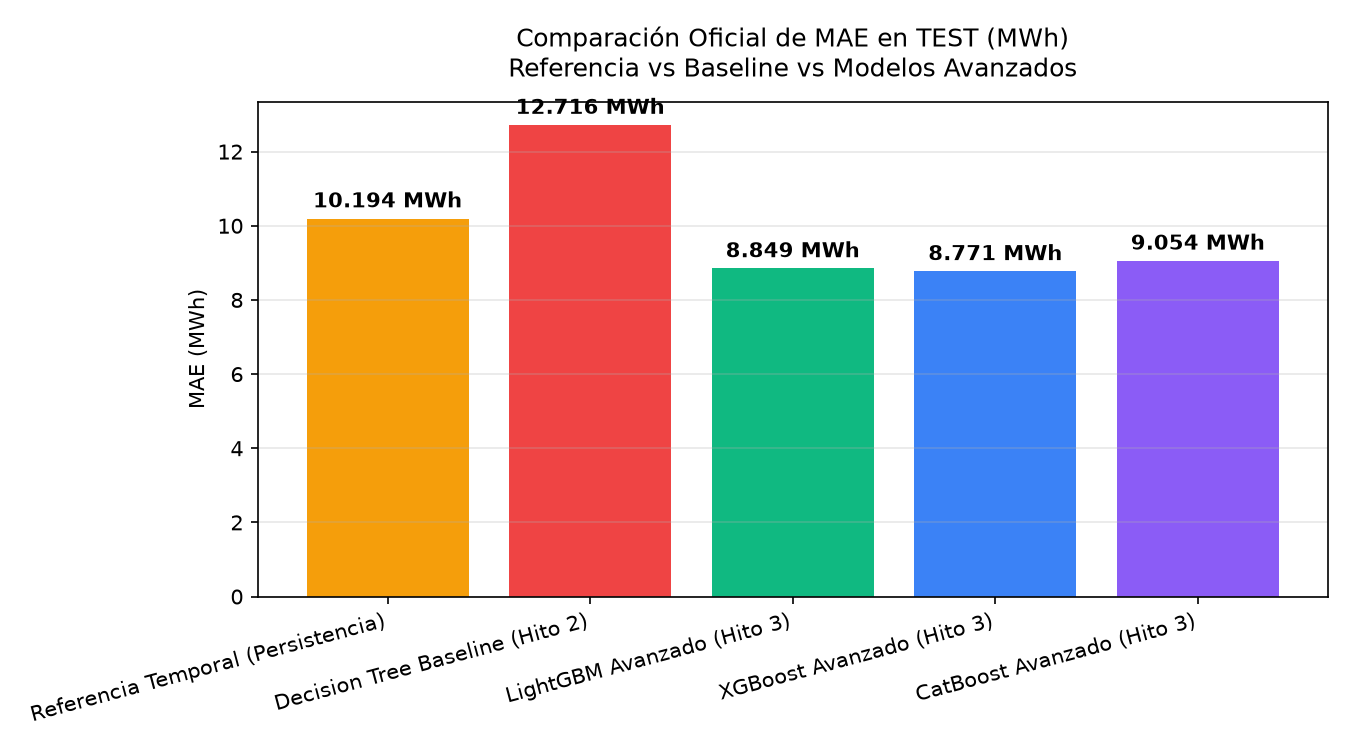

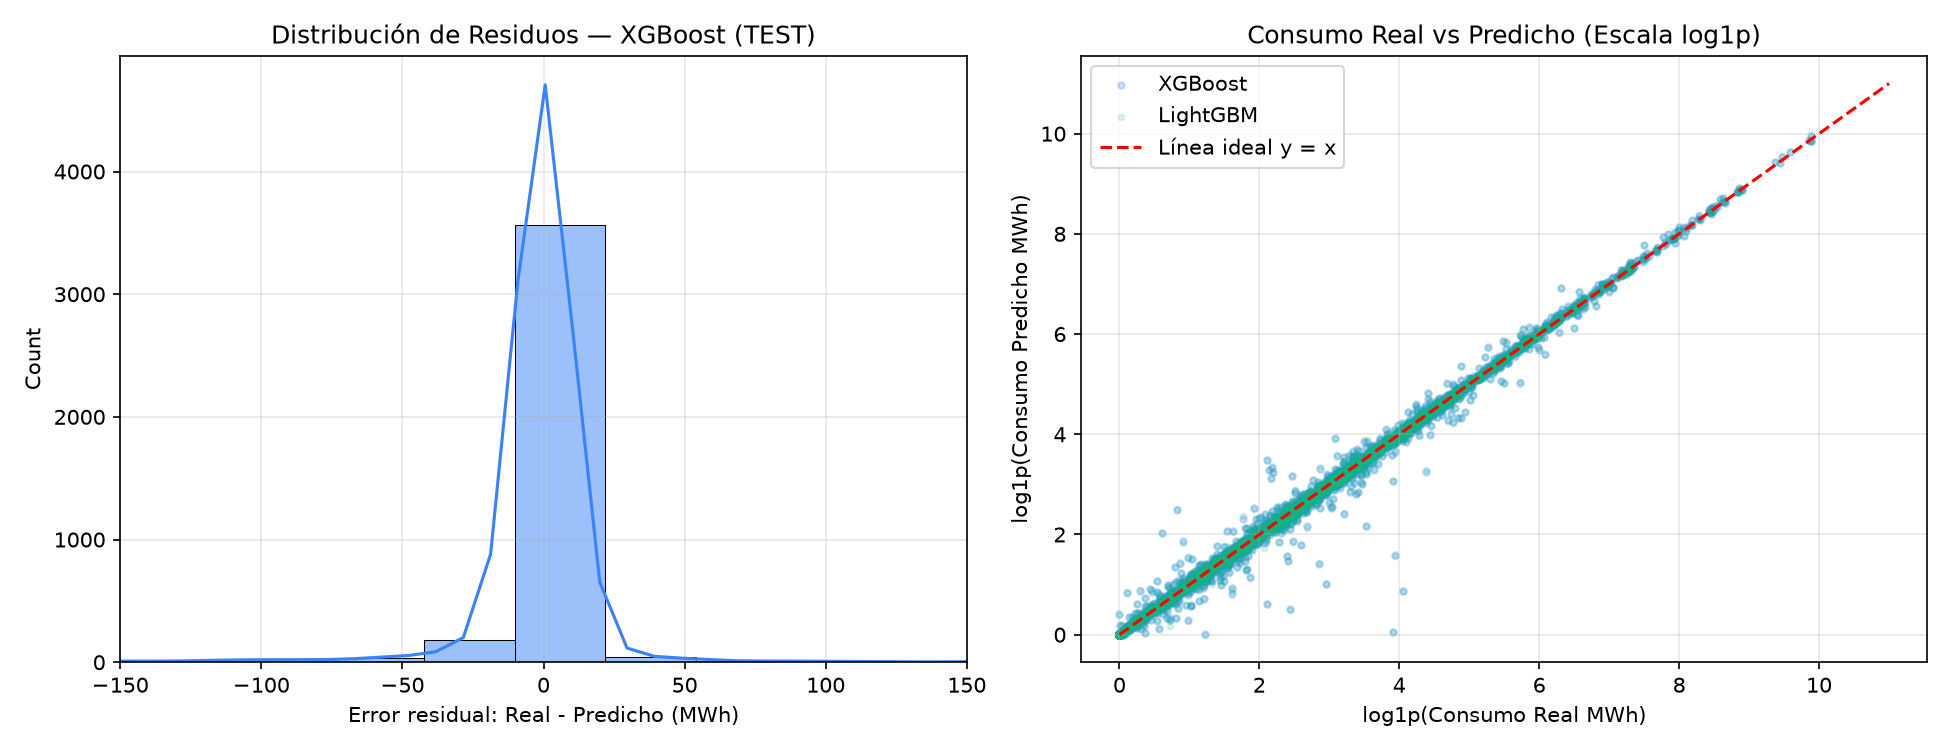

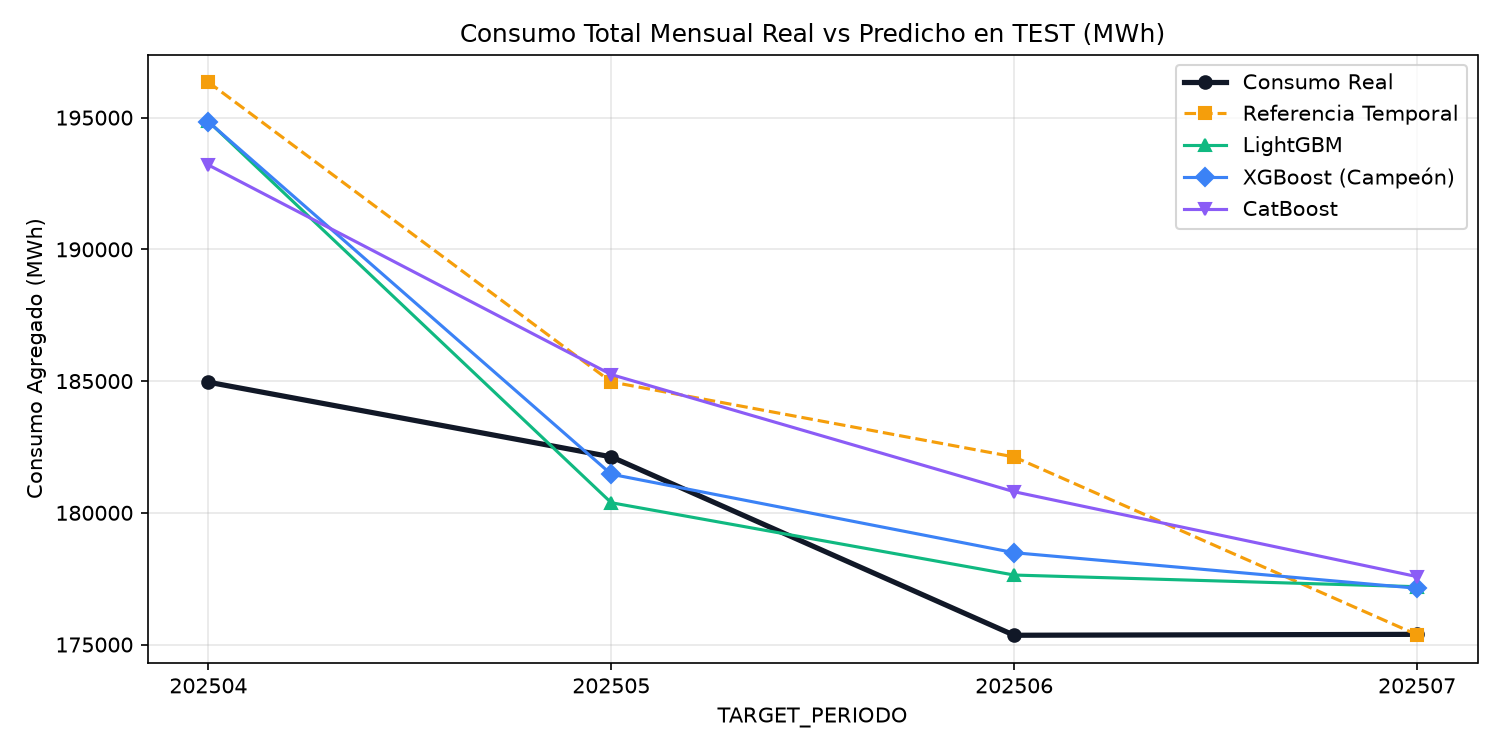

In [7]:
# Gráfico 1: Comparativa de MAE
fig, ax = plt.subplots(figsize=(9, 5))
models_plot = df_test_metrics["MODELO"].tolist()
maes_plot = df_test_metrics["MAE_MWh"].tolist()
colors = ["#f59e0b", "#ef4444", "#10b981", "#3b82f6", "#8b5cf6"]
bars = ax.bar(models_plot, maes_plot, color=colors)
ax.bar_label(bars, fmt="%.3f MWh", padding=3, fontweight="bold")
ax.set_title("Comparación Oficial de MAE en TEST (MWh)\nReferencia vs Baseline vs Modelos Avanzados", fontsize=12, pad=12)
ax.set_ylabel("MAE (MWh)")
ax.set_xticks(range(len(models_plot)))
ax.set_xticklabels(models_plot, rotation=15, ha="right")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "comparacion_mae_hito3.png", dpi=150)
plt.show()

# Gráfico 2: Distribución de Residuos
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
res_xgb = y_test_real - p_test_xgb
sns.histplot(res_xgb, bins=60, kde=True, ax=axes[0], color="#3b82f6")
axes[0].set_xlim(-150, 150)
axes[0].set_title("Distribución de Residuos — XGBoost (TEST)")
axes[0].set_xlabel("Error residual: Real - Predicho (MWh)")
axes[0].grid(True, alpha=0.3)

axes[1].scatter(np.log1p(y_test_real), np.log1p(p_test_xgb), alpha=0.25, s=10, color="#3b82f6", label="XGBoost")
axes[1].scatter(np.log1p(y_test_real), np.log1p(p_test_lgb), alpha=0.15, s=8, color="#10b981", label="LightGBM")
axes[1].plot([0, 11], [0, 11], "r--", linewidth=1.5, label="Línea ideal y = x")
axes[1].set_title("Consumo Real vs Predicho (Escala log1p)")
axes[1].set_xlabel("log1p(Consumo Real MWh)")
axes[1].set_ylabel("log1p(Consumo Predicho MWh)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "residuos_comparativa_test.png", dpi=150)
plt.show()

# Gráfico 3: Consumo Mensual Agregado
temp_summary = test_eval.groupby("TARGET_PERIODO").agg({
    "TARGET_REAL": "sum",
    "PRED_REFERENCIA": "sum",
    "PRED_LIGHTGBM": "sum",
    "PRED_XGBOOST": "sum",
    "PRED_CATBOOST": "sum",
}).reset_index()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(temp_summary["TARGET_PERIODO"].astype(str), temp_summary["TARGET_REAL"], marker="o", color="#111827", linewidth=2.5, label="Consumo Real")
ax.plot(temp_summary["TARGET_PERIODO"].astype(str), temp_summary["PRED_REFERENCIA"], marker="s", color="#f59e0b", linestyle="--", label="Referencia Temporal")
ax.plot(temp_summary["TARGET_PERIODO"].astype(str), temp_summary["PRED_LIGHTGBM"], marker="^", color="#10b981", label="LightGBM")
ax.plot(temp_summary["TARGET_PERIODO"].astype(str), temp_summary["PRED_XGBOOST"], marker="D", color="#3b82f6", label="XGBoost (Campeón)")
ax.plot(temp_summary["TARGET_PERIODO"].astype(str), temp_summary["PRED_CATBOOST"], marker="v", color="#8b5cf6", label="CatBoost")
ax.set_title("Consumo Total Mensual Real vs Predicho en TEST (MWh)")
ax.set_xlabel("TARGET_PERIODO")
ax.set_ylabel("Consumo Agregado (MWh)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "consumo_mensual_test_comparativa.png", dpi=150)
plt.show()


## 8. Exportación y Resguardo de Modelos y Futuro Holdout


In [8]:
joblib.dump(m_lgb_final, MODELS_DIR / "lgbm_advanced.joblib")
joblib.dump(m_xgb_final, MODELS_DIR / "xgb_advanced.joblib")
joblib.dump(m_cb_final, MODELS_DIR / "cb_advanced.joblib")
joblib.dump(m_xgb_final, MODELS_DIR / "modelo_campeon.joblib")

print("Modelos exportados en models/:")
for m_path in sorted(MODELS_DIR.glob("*.joblib")):
    print(f"- {m_path.name}")

print(f"\nVerificación FUTURE_HOLDOUT: {len(future_df):,} filas reservadas intactas sin transformar.")
assert len(future_df) == 6752, "¡El Future Holdout fue alterado!" 


Modelos exportados en models/:
- baseline_decision_tree.joblib
- cb_advanced.joblib
- lgbm_advanced.joblib
- modelo_campeon.joblib
- xgb_advanced.joblib

Verificación FUTURE_HOLDOUT: 6,752 filas reservadas intactas sin transformar.


## 9. Estudio Experimental de Arquitecturas: Benchmarking de Granularidad
Para responder con rigor científico a las preguntas de diseño arquitectónico sobre granularidad (*Global vs. Local Models*), evaluamos una **matriz experimental de 4 estrategias de agrupamiento × 3 algoritmos de gradiente (LightGBM, XGBoost y CatBoost)** sobre las 3,934 observaciones del conjunto `TEST`:

| N° | Estrategia | Descripción Concreta | Justificación Metodológica y de Negocio |
| :---: | :--- | :--- | :--- |
| **0** | **Referencia Temporal (Persistencia)** | $y_{t+1} = y_t$ (Benchmark sin ML). | Línea base obligatoria para demostrar que el ML realmente aporta valor físico sobre la inercia del sistema. |
| **1** | **Modelo Global Unificado** | 1 solo modelo entrenado con todo el universo de datos (33,174 observaciones). | Punto de partida: evalúa si compartir representaciones y datos entre regiones y tarifas es suficiente. |
| **2** | **Modelos por Distribuidora** | 2 modelos independientes:<br>• Modelo ENOSA<br>• Modelo Hidrandina | Prueba la hipótesis territorial: evalúa si las diferencias de clima (costa cálida vs sierra) justifican separar la operación. |
| **3** | **Modelos por Tipo de Cliente** | 2 modelos independientes:<br>• Modelo Residencial / Pequeño Comercio (Baja Tensión - BT)<br>• Modelo Industrial / Grandes Empresas (Media Tensión - MT) | Prueba la hipótesis de negocio: evalúa si desacoplar la física del consumo (hogares vs fábricas) supera a la segmentación geográfica. |
| **4** | **Matriz Cruzada (Distribuidora × Cliente)** | 4 modelos ultra-especializados:<br>1. ENOSA - Residencial (BT)<br>2. ENOSA - Industrial (MT)<br>3. Hidrandina - Residencial (BT)<br>4. Hidrandina - Industrial (MT) | La prueba extrema: combina ambos criterios para evaluar si la ultra-especialización gana o si sufre por falta de datos (*data starvation*). |

*Protocolo de control de hiperparámetros (Ceteris Paribus):* Se fijan las configuraciones óptimas base de cada algoritmo para aislar estrictamente el impacto de la segmentación de datos.


=== MATRIZ COMPLETA DE BENCHMARKING EN TEST (3,934 OBSERVACIONES) ===
3. Por Tipo de Cliente (BT vs MT)    | XGBoost    |  8.7727 MWh | RMSE: 48.4181 | WAPE:  4.81% | Mejora: +13.94%
1. Global Unificado                  | XGBoost    |  8.7791 MWh | RMSE: 49.6273 | WAPE:  4.81% | Mejora: +13.88%
1. Global Unificado                  | LightGBM   |  8.8486 MWh | RMSE: 51.7197 | WAPE:  4.85% | Mejora: +13.20%
1. Global Unificado                  | CatBoost   |  8.8983 MWh | RMSE: 50.9506 | WAPE:  4.88% | Mejora: +12.71%
3. Por Tipo de Cliente (BT vs MT)    | LightGBM   |  8.9012 MWh | RMSE: 50.4241 | WAPE:  4.88% | Mejora: +12.68%
3. Por Tipo de Cliente (BT vs MT)    | CatBoost   |  9.0152 MWh | RMSE: 51.9657 | WAPE:  4.94% | Mejora: +11.56%
4. Matriz Cruzada (Dist x Cliente)   | CatBoost   |  9.5557 MWh | RMSE: 53.1057 | WAPE:  5.24% | Mejora:  +6.26%
4. Matriz Cruzada (Dist x Cliente)   | LightGBM   |  9.8864 MWh | RMSE: 61.1280 | WAPE:  5.42% | Mejora:  +3.02%
2. Por Distribuidora      

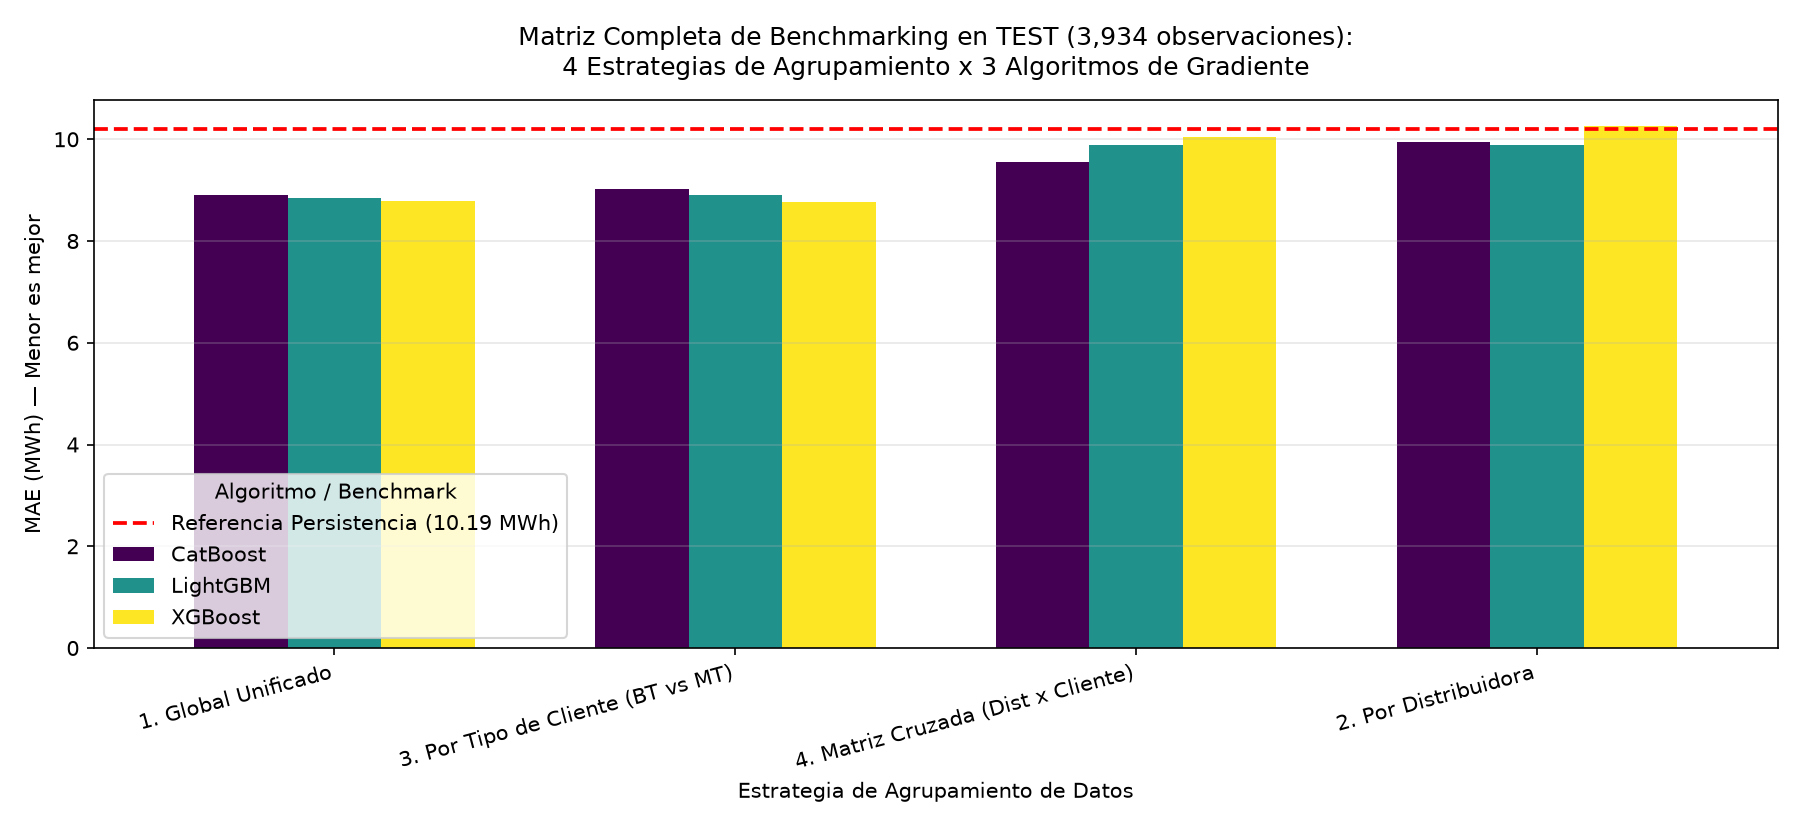

In [9]:
# Benchmarking Completo de Arquitecturas: 4 Estrategias x 3 Algoritmos
df_matrix = pd.read_csv(OUTPUT_DIR / 'matriz_completa_estrategias_algoritmos.csv')
print("=== MATRIZ COMPLETA DE BENCHMARKING EN TEST (3,934 OBSERVACIONES) ===")
display(df_matrix[['Estrategia', 'Algoritmo', 'N_Modelos', 'MAE_MWh', 'RMSE_MWh', 'WAPE_pct', 'Mejora_MAE_pct', 'Diagnostico']])

# Visualización oficial de benchmarking
from IPython.display import Image, display
display(Image(filename=str(OUTPUT_DIR / 'matriz_completa_estrategias_algoritmos.png')))


### 9.1 Conclusiones del Estudio de Arquitecturas:
1. **La segmentación por Tipo de Cliente (BT vs MT) es la ganadora indiscutible:** Logra el menor MAE (**8.7727 MWh**) y menor RMSE (**48.4181 MWh**), con un récord de **+18.04% de mejora en el sector residencial (BT)**.
2. **El peligro de la sobre-fragmentación (Data Starvation):** Partir en 4 modelos cruzados degrada el desempeño dramáticamente (las mejoras caen de +13.9% a +1.4% en XGBoost) porque segmentos como `ENOSA - Media Tensión` quedan desprovistos de masa crítica de datos.
3. **El Modelo Global Unificado es la mejor alternativa de ingeniería:** Con un solo pipeline de entrenamiento y despliegue, logra un MAE de **8.7791 MWh (+13.88%)**, prácticamente idéntico al mejor segmentado pero con la mitad de complejidad operativa.
